# RFM

In [1]:
import pandas as pd

orders = pd.read_csv('data/orders_clean.csv', parse_dates=['order_purchase_timestamp'])
customers = pd.read_csv('data/customers_clean.csv')
payments = pd.read_csv('data/order_payments_clean.csv')

# 1. 只取已完成订单，关联真实客户ID和支付金额
df = (orders[orders['order_status'] == 'delivered']
      .merge(customers[['customer_id', 'customer_unique_id']], on='customer_id')
      .merge(payments.groupby('order_id')['payment_value'].sum().rename('payment_value'), on='order_id'))

# 2. 快照日 = 数据里最后一天 + 1，计算 RFM 三个原始值
snapshot = df['order_purchase_timestamp'].max() + pd.Timedelta(days=1)
rfm = df.groupby('customer_unique_id').agg(
    R=('order_purchase_timestamp', lambda x: (snapshot - x.max()).days),
    F=('order_id', 'nunique'),
    M=('payment_value', 'sum'))

# 3. 打分：R 越近分越高；F 因复购太少直接取原值(1~5)；M 用 rank 避免 qcut 重复值报错
rfm['R_score'] = pd.qcut(rfm['R'], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['F_score'] = rfm['F'].clip(1, 5)
rfm['M_score'] = pd.qcut(rfm['M'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)

# 4. 按 R/F 高低(≥3为高)归入 4 类
def seg(row):
    r, f = row.R_score >= 3, row.F_score >= 3
    if r and f:     return '重要价值客户'
    if not r and f: return '重要保持客户'
    if r and not f: return '重要发展客户'
    return '重要挽留客户'
rfm['segment'] = rfm.apply(seg, axis=1)

print(rfm['segment'].value_counts())

segment
重要发展客户    55983
重要挽留客户    37146
重要价值客户      159
重要保持客户       69
Name: count, dtype: int64


## RFM 分析结论

### 1. 客户结构
- **复购率仅 3.0%**：93% 的客户只购买过一次，平台以一次性交易为主，客户分层主要依靠 R（活跃度）和 M（消费力）区分。
- **重要发展客户占 60%**（55,983 人，平均 R≈134 天）：处于活跃期但仅购买一次，是平台的客户主体。
- **重要挽留客户占 40%**（37,146 人，平均 R≈395 天）：距上次购买已超过一年，流失风险高。
- **高价值复购客户仅 228 人（0.24%）**：人数极少但人均消费约 542，是整体人均（约 165）的 3 倍多。

### 2. 价值贡献
- 发展客户贡献约 **59.5%** 总金额，挽留客户约 **39.7%**，两者合计覆盖 99.8% 的客户和 99.2% 的销售额。
- 复购客户（价值+保持客群）人数不足 0.3%，人均消费却远超均值，说明复购客户的单客价值明显更高。

### 3. 运营建议
- **发展客户（60%）**：首购后 30 天内是唤醒窗口，通过优惠券、关联品类推荐促进二次购买；复购率每提升 1 个百分点，约新增 900 名复购客户。
- **挽留客户（40%）**：获客成本回收价值低，适合邮件等低成本召回，不宜大量投放广告。
- **价值/保持客户（228 人）**：提供会员级权益重点维护，同时作为复购运营模型的小样本试点。

## 各客群人数与金额占比

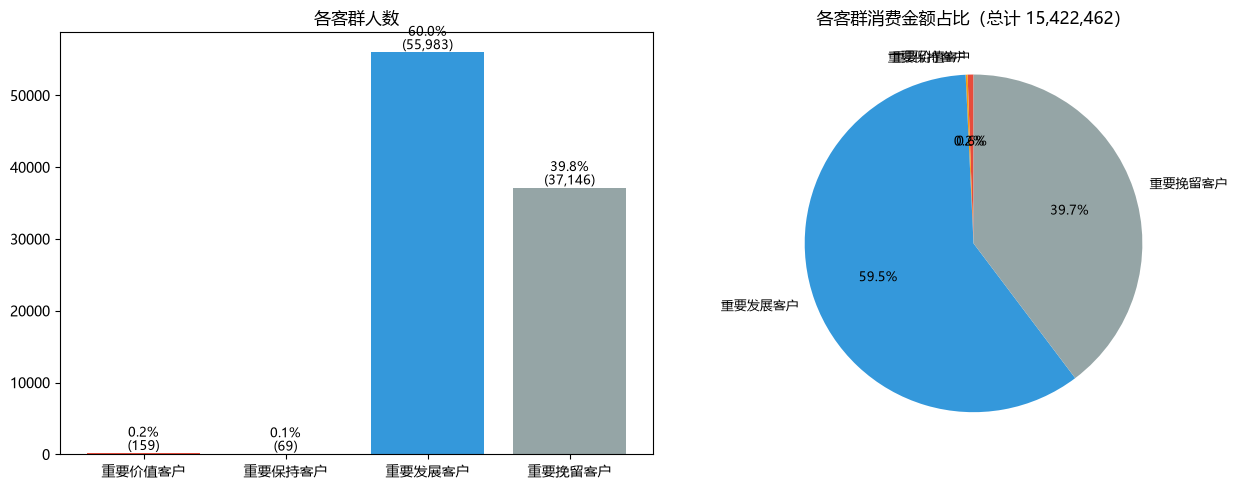

In [2]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

order = ['重要价值客户', '重要保持客户', '重要发展客户', '重要挽留客户']
stats = rfm.groupby('segment').agg(人数=('R', 'size'), 总金额=('M', 'sum')).loc[order]
colors = ['#e74c3c', '#f39c12', '#3498db', '#95a5a6']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 左图：各客群人数
axes[0].bar(range(4), stats['人数'], color=colors)
axes[0].set_xticks(range(4), stats.index)
axes[0].set_title('各客群人数')
for i, v in enumerate(stats['人数']):
    axes[0].text(i, v, f'{v/len(rfm):.1%}\n({v:,})', ha='center', va='bottom', fontsize=9)

# 右图：各客群消费金额占比
axes[1].pie(stats['总金额'], labels=stats.index, autopct='%.1f%%',
            colors=colors, startangle=90, textprops={'fontsize': 9})
axes[1].set_title(f"各客群消费金额占比（总计 {stats['总金额'].sum():,.0f}）")

plt.tight_layout()
plt.show()

## 业务解读

- 93,357 名客户中 93% 只买过一次——Olist 本质是「一次性交易平台」，这与巴西电商早期获客驱动的市场环境一致，不是产品缺陷。
- 60/40 的「活跃/流失」结构意味着：运营主战场不是维护忠诚客户（只有 228 人），而是**延长新客户的活跃窗口**和**低成本召回流失客户**。
- F 几乎无区分度时，RFM 退化为 R×M 二维分层——这提示纯交易数据的价值上限，也再次说明行为数据（浏览/加购）的稀缺是分析瓶颈。
- 228 名高价值复购客户人均消费 542（均值 165 的 3.3 倍），是最值得做深访/问卷的小样本种子人群。

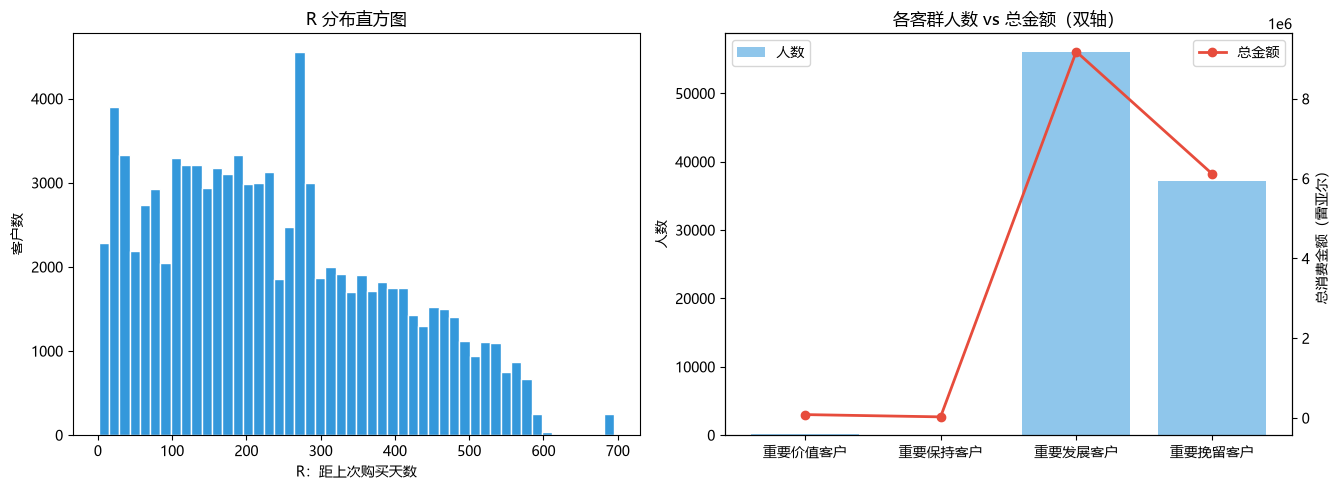

In [3]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))

# ① R 分布直方图
axes[0].hist(rfm['R'], bins=50, color='#3498db', edgecolor='white')
axes[0].set_xlabel('R：距上次购买天数'); axes[0].set_ylabel('客户数')
axes[0].set_title('R 分布直方图')

# ② 各客群人数（柱，左轴）与总金额（折线，右轴）
seg_order = ['重要价值客户', '重要保持客户', '重要发展客户', '重要挽留客户']
seg_stats = rfm.groupby('segment').agg(人数=('R', 'size'), 总金额=('M', 'sum')).reindex(seg_order)
xs = list(range(len(seg_order)))
axes[1].bar(xs, seg_stats['人数'], color='#3498db', alpha=.55, label='人数')
ax2 = axes[1].twinx()
ax2.plot(xs, seg_stats['总金额'], color='#e74c3c', marker='o', lw=2, label='总金额')
axes[1].set_xticks(xs, seg_order)
axes[1].set_ylabel('人数'); ax2.set_ylabel('总消费金额（雷亚尔）')
axes[1].set_title('各客群人数 vs 总金额（双轴）')
axes[1].legend(loc='upper left'); ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()